# 26장 · LangGraph StateGraph의 상태와 노드

StateGraph의 노드는 현재 상태를 읽고 바꿀 필드를 반환합니다. 간선은 그 변경을 반영한 뒤 어느 노드를 실행할지 정합니다.

도서 대출 기간을 물었더니 검색 함수가 문장 목록을 돌려줬습니다. 화면에 띄울 답은 한 문장입니다. 세 함수에 같은 상태를 건네고 각 함수가 어느 칸만 바꾸는지 따라갑니다. 이 장부터 수업용 Python 커널에 LangGraph와 langchain-core가 필요합니다. 검색과 문장 작성에는 로컬 규칙을 씁니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langgraph 1.2.16입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## TypedDict와 노드의 부분 갱신

State는 한 질문을 처리하면서 여러 단계가 함께 읽는 값입니다. 여기서는 question에 질문, documents에 찾은 문장 목록, answer에 최종 안내를 담습니다. 노드가 값을 읽어 바꿀 부분만 돌려주면 그래프가 앞 상태에 합칩니다.

<!-- lesson-visual visual-three-fields -->
**노드 하나가 반환하지 않은 필드는 어디로 갈까요?**

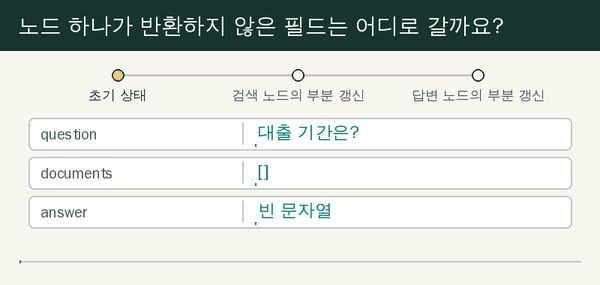

검색 노드는 documents만, 답변 노드는 answer만 돌려줍니다. 각 갱신이 합쳐진 뒤에도 처음 받은 question은 상태에 남습니다.
<!-- /lesson-visual visual-three-fields -->


### 노드 실행 순서와 공유 상태

<p>Node는 이번에 실행할 Python 함수입니다. Edge는 어떤 함수 다음에 어떤 함수를 실행할지 정한 연결입니다. State는 실행 중 공유하는 값의 묶음입니다. 문서가 어디에 저장되는지와 어느 함수가 다음에 호출되는지를 한 용어로 섞으면 오류 원인을 찾기 어렵습니다.</p>

<p>예를 들어 질문의 공백을 지우는 normalize는 question을 읽고 question만 갱신합니다. 문서를 고르는 lookup은 question을 읽고 documents를 갱신합니다. 답변을 만드는 compose는 documents를 읽고 answer를 갱신합니다. 이번 그래프에서는 모델이 다음 노드를 고르지 않고 코드의 고정된 연결을 따릅니다.</p>

<table><caption>세 요소를 코드에 대응하기</caption><thead><tr><th scope="col">요소</th><th scope="col">예제</th><th scope="col">변경의 의미</th></tr>
</thead><tbody><tr><td>Node</td><td>normalize, lookup, compose</td><td>처리할 계산을 바꿈</td></tr>
<tr><td>Edge</td><td>normalize → lookup</td><td>실행 순서를 바꿈</td></tr>
<tr><td>State</td><td>question, documents, answer</td><td>전달하고 보관할 값을 바꿈</td></tr>
</tbody></table>


### 셀 01 · normalize()의 공백 정리

normalize가 돌려줄 딕셔너리의 키를 예측해 보세요.


In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    documents: list[str]
    answer: str

def normalize(state: State) -> dict:
    question = state["question"].strip()
    if not question:
        raise ValueError("질문을 입력하세요.")
    return {"question": question}

initial = {'question': '  대출 기간은?  ', 'documents': [], 'answer': ''}
print(normalize(initial))

{'question': '대출 기간은?'}


question 하나만 보입니다. strip이 앞뒤 공백을 뺐고, normalize는 문서나 답변을 만들지 않았습니다. 이 반환값을 다음 단계의 전체 상태로 넘기면 나머지 키가 사라집니다.


### TypedDict 상태 스키마

<p>State는 실행 중 사용할 딕셔너리의 키와 값 형태를 적은 타입입니다. question은 질문 문자열, documents는 문장 문자열의 리스트, answer는 답변 문자열입니다. 실제 값은 graph.invoke에 넘기는 initial에 들어 있습니다. 타입 선언만으로 질문이 자동 생성되지는 않습니다.</p>

<p>TypedDict는 정적 타입 확인을 돕는 선언입니다. 잘못된 자료형이나 빈 입력을 모든 경우 자동으로 막아 주는 런타임 검증기로 생각하지 마세요. 이번 예제는 question.strip() 결과가 비었는지 노드에서 직접 검사합니다.</p>

<table><caption>초기 상태 예측</caption><thead><tr><th scope="col">키</th><th scope="col">초기 값</th><th scope="col">누가 갱신하나요?</th></tr>
</thead><tbody><tr><td>question</td><td>"  대출 기간은?  "</td><td>normalize</td></tr>
<tr><td>documents</td><td>[]</td><td>lookup</td></tr>
<tr><td>answer</td><td>""</td><td>compose</td></tr>
</tbody></table>


### 셀 02 · 노드 반환값과 상태 병합

직접 호출에서는 딕셔너리를 합쳐 그래프가 하는 일을 한 번 따라 해 봅니다.


In [2]:
normalized = {**initial, **normalize(initial)}
print(normalized)

{'question': '대출 기간은?', 'documents': [], 'answer': ''}


documents와 answer의 빈 값이 남습니다. 두 칸은 이제 검색과 답변 노드가 채울 자리입니다.


### 노드 함수의 부분 갱신

<p>normalize가 반환한 딕셔너리에는 question 하나만 있습니다. 반환에서 빠진 documents와 answer를 지우라는 뜻이 아닙니다. 이번처럼 별도 갱신 규칙을 지정하지 않은 필드는 해당 키가 반환되면 새 값으로 바뀌며, 반환하지 않은 필드는 유지됩니다.</p>

<p>입력 딕셔너리의 값을 직접 바꿔 놓고 아무것도 반환하지 않는 방식을 피합니다. 갱신할 내용을 새 딕셔너리로 반환하면 노드의 책임과 검사할 결과가 분명해집니다. 이 장은 순차 실행만 다루며 여러 노드가 동시에 같은 키를 갱신하는 경우는 포함하지 않습니다.</p>


## add_node()·add_edge()·compile()로 그래프 연결

엣지는 어떤 함수를 다음에 부를지 정하는 연결입니다. START에서 normalize, lookup, compose 순으로 연결한 뒤 END에서 멈춥니다. 검색 결과를 미리 써 넣지 않고 질문에 들어 있는 낱말을 자료와 대조합니다.

### 초기 상태와 세 노드의 변경값

**초기 상태 만들기**　질문을 넣고 결과 칸은 비웁니다.

```
question  = '  대출 기간은?  '
documents = []
answer    = ""
```

**질문의 공백 제거**　question만 갱신하고 다른 키는 유지합니다.

```
question  = '대출 기간은?'
documents = []
answer    = ""
```

**질문에 맞는 문장 조회**　가상 문서 중 대출 키워드가 맞는 문장을 고릅니다.

```
question  = '대출 기간은?'
documents = ["도서 대출 기간은 14일입니다."]
answer    = ""
```

**문서를 답변으로 연결**　documents를 읽고 answer를 갱신합니다.

```
question  = '대출 기간은?'
documents = ["도서 대출 기간은 14일입니다."]
answer    = "도서 대출 기간은 14일입니다."
```


### compile()까지는 어떤 노드도 실행되지 않습니다

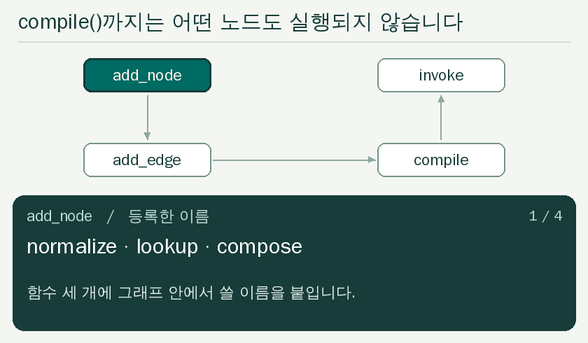

빌더에서 이름과 간선을 등록해 실행 경로를 완성합니다. 첫 상태는 graph.invoke(initial)에서 들어갑니다.


### 셀 03 · StateGraph의 노드와 간선

이번 셀의 lookup은 노트북 안에 넣어 둔 두 가상 문장에서 찾습니다. 등록된 노드 이름과 엣지의 이름을 맞춰 보세요.

초기값부터 normalize, lookup, compose 순서로 따라가세요. 한 노드가 돌려주는 사전은 이번에 바꿀 칸만 담습니다. 나머지 두 칸은 앞 상태의 값을 유지합니다.


In [3]:
rows = [{'id': 'library-1', 'keyword': '대출', 'text': '도서 대출 기간은 14일입니다.'},
 {'id': 'library-2', 'keyword': '휴관', 'text': '도서관은 월요일에 휴관합니다.'}]

def lookup(state):
    found = [r['text'] for r in rows if r['keyword'] in state['question']]
    return {'documents': found}

def compose(state: State) -> dict:
    documents = state["documents"]
    answer = " / ".join(documents) if documents else "제공된 문서에서 확인할 수 없습니다."
    return {"answer": answer}

def make_graph():
    builder = StateGraph(State)
    builder.add_node("normalize", normalize)
    builder.add_node("lookup", lookup)
    builder.add_node("compose", compose)
    builder.add_edge(START, "normalize")
    builder.add_edge("normalize", "lookup")
    builder.add_edge("lookup", "compose")
    builder.add_edge("compose", END)
    return builder.compile()

graph = make_graph()
print(graph.invoke(initial)['answer'])

도서 대출 기간은 14일입니다.


14일이라는 문장이 나옵니다. lookup이 대출 문장을 골라 documents에 넣었고 compose는 그대로 이어 붙였습니다. 모델에 날짜를 묻는 과정은 없습니다.


### 노드·간선 등록과 컴파일

<p>StateGraph는 그래프를 만드는 빌더입니다. add_node의 첫 인자는 그래프에서 사용하는 이름이고 두 번째 인자는 실행할 함수입니다. add_edge는 등록한 이름으로 연결합니다. START는 입력을 받은 시작 위치, END는 종료 위치입니다.</p>

<p>compile로 실행 가능한 그래프를 만든 뒤 invoke를 호출합니다. 컴파일 단계가 실제 문서 내용의 품질이나 모든 런타임 오류를 증명해 주지는 않습니다. 문서 파일 누락처럼 실행할 때 드러나는 문제도 직접 검사해야 합니다.</p>


### 노드 반환값과 invoke()의 최종 상태

<p>normalize(initial)은 question 한 칸을 돌려줍니다. graph.invoke(initial)은 세 노드를 거친 뒤 question·documents·answer를 모두 돌려줍니다. 셀 03에서 마지막에 선택한 키는 answer입니다. 휴관 문서 자체를 확인할 때는 documents를 읽습니다.</p>


### 같은 상태에서 세 노드가 한 칸씩 채웁니다

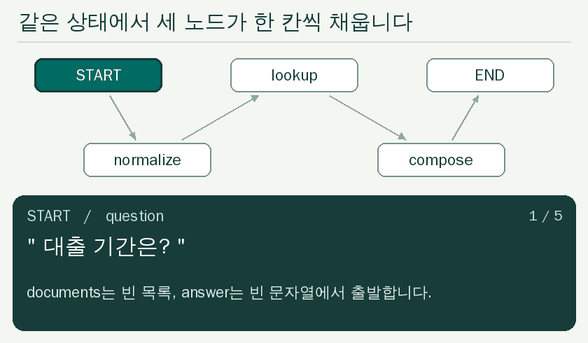

실행 중인 노드가 바뀔 때 반환 키도 바뀝니다. lookup이 찾은 문장은 compose가 answer를 쓴 뒤에도 documents에 남습니다.


### 과제 04 · invoke() 결과의 근거 확인

질문을 ‘휴관 요일은?’로 바꾸어 실행하고 최종 상태에서 documents만 표시하세요.


In [4]:
# 초기 상태의 질문을 바꾼 뒤 그래프에 넘기세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>request = {**initial, &#x27;question&#x27;: &#x27;휴관 요일은?&#x27;}
print(graph.invoke(request)[&#x27;documents&#x27;])</code></pre>
<p>실행 결과</p><pre><code>[&#x27;도서관은 월요일에 휴관합니다.&#x27;]</code></pre>
<p>휴관에 해당하는 문장 한 개가 목록에 남습니다. answer가 문자열인 데 비해 이 칸은 검색이 여러 건일 수 있어 목록입니다.</p>
</details>


## 돌아보기

주차 질문을 넣었을 때 답변을 만든 노드와 빈 목록을 만든 노드를 구별해 보세요. 다음 장은 빈 검색 뒤 한 번 더 찾을지 결정합니다.
